### Question 1: Script for Descriptive Analysis

In [4]:
import pandas as pd

df = pd.read_csv('students.csv')

def Desc_stat(ds, var):
    mean = ds[var].mean()
    median = ds[var].median()
    mode = ds[var].mode()[0]
    minimum = ds[var].min()
    maximum = ds[var].max()
    data_range = maximum - minimum
    std_dev = ds[var].std()
    variance = ds[var].var()
    skewness = ds[var].skew()
    kurtosis = ds[var].kurt()
    q1 = ds[var].quantile(0.25)
    q2 = ds[var].quantile(0.50)
    q3 = ds[var].quantile(0.75)
    iqr = q3 - q1
    count = ds[var].count()

    summary = {
        'Mean': mean,
        'Median': median,
        'Mode': mode,
        'Minimum': minimum,
        'Maximum': maximum,
        'Range': data_range,
        'Standard Deviation': std_dev,
        'Variance': variance,
        'Skewness': skewness,
        'Kurtosis': kurtosis,
        '25th Percentile': q1,
        '50th Percentile': q2,
        '75th Percentile': q3,
        'Interquartile Range': iqr,
        'Count': count
    }

    return summary

print(pd.Series(Desc_stat(df, 'overall_gpa')))

Mean                       3.123890
Median                     3.180000
Mode                       4.000000
Minimum                    0.770000
Maximum                    4.000000
Range                      3.230000
Standard Deviation         0.579559
Variance                   0.335889
Skewness                  -0.519026
Kurtosis                  -0.180976
25th Percentile            2.730000
50th Percentile            3.180000
75th Percentile            3.580000
Interquartile Range        0.850000
Count                  10000.000000
dtype: float64


### Question 2: Random Sampling

In [5]:
import pandas as pd

df = pd.read_csv('students.csv')

# Select 150 students randomly
sample_size = 150
ds = df.sample(n=sample_size, replace=False, random_state=42)

# Apply the descriptive statistics function
print("Random Sample Size:", len(ds))
print(pd.Series(Desc_stat(ds, 'overall_gpa')))

Random Sample Size: 150
Mean                     3.153200
Median                   3.245000
Mode                     3.270000
Minimum                  1.680000
Maximum                  4.000000
Range                    2.320000
Standard Deviation       0.581380
Variance                 0.338003
Skewness                -0.561772
Kurtosis                -0.336771
25th Percentile          2.765000
50th Percentile          3.245000
75th Percentile          3.580000
Interquartile Range      0.815000
Count                  150.000000
dtype: float64


### Question 3: Systematic Sampling

In [6]:
import pandas as pd

# Load the dataset
df = pd.read_csv("students.csv")

# Set the sample size
sample_size = 150

# Calculate the sampling interval
interval = len(df) // sample_size

# Select every 66th record
systematic_sample = df.iloc[::interval].head(sample_size)

# Display the sample size and interval
print("Systematic Sample Size:", len(systematic_sample))
print("Sampling Interval:", interval)

# Apply the descriptive statistics function
print("Descriptive Statistics for Overall GPA:")
print(pd.Series(Desc_stat(systematic_sample, 'overall_gpa')))

Systematic Sample Size: 150
Sampling Interval: 66
Descriptive Statistics for Overall GPA:
Mean                     3.132867
Median                   3.175000
Mode                     4.000000
Minimum                  1.850000
Maximum                  4.000000
Range                    2.150000
Standard Deviation       0.557555
Variance                 0.310868
Skewness                -0.218189
Kurtosis                -0.808659
25th Percentile          2.702500
50th Percentile          3.175000
75th Percentile          3.575000
Interquartile Range      0.872500
Count                  150.000000
dtype: float64


### Question 4: Descriptive Statistical Report

In [7]:
# Descriptive Statistical Report

# Select the dependent variable from the systematic sample
gpa = systematic_sample['overall_gpa']

# Find how many times the mode appears
print("Mode Frequency:", gpa.value_counts()[gpa.mode()[0]])

# Compare the mean GPA values
print("Systematic Sample Mean:", round(gpa.mean(), 4))
print("Random Sample Mean:", round(ds['overall_gpa'].mean(), 4))
print("Full Dataset Mean:", round(df['overall_gpa'].mean(), 4))

# Compare the minimum GPA values
print("Systematic Sample Minimum:", gpa.min())
print("Full Dataset Minimum:", df['overall_gpa'].min())

# Compare the standard deviation
print("Systematic Sample Std:", round(gpa.std(), 4))
print("Full Dataset Std:", round(df['overall_gpa'].std(), 4))

Mode Frequency: 8
Systematic Sample Mean: 3.1329
Random Sample Mean: 3.1532
Full Dataset Mean: 3.1239
Systematic Sample Minimum: 1.85
Full Dataset Minimum: 0.77
Systematic Sample Std: 0.5576
Full Dataset Std: 0.5796


### Question 5: Visualisation 

#### a. Scatter Plot

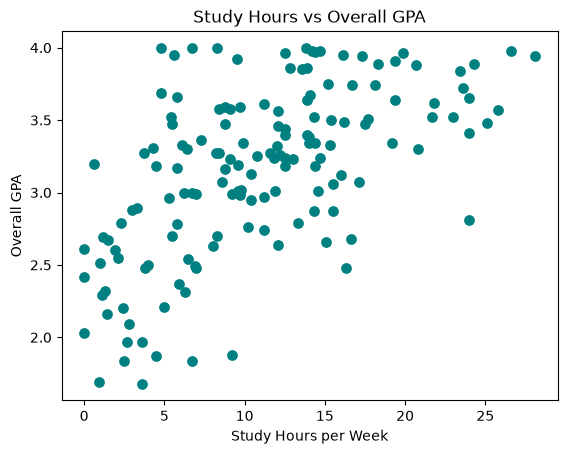

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('students.csv')

# Select a random sample of 150 students
sample = df.sample(n=150, replace=False, random_state=42)

# Create a scatter plot
sample.plot.scatter(x='study_hours_per_week',
                    y='overall_gpa',
                    s=45, c='teal')

plt.xlabel('Study Hours per Week')
plt.ylabel('Overall GPA')
plt.title('Study Hours vs Overall GPA')
plt.show()

#### b. Box Plot 

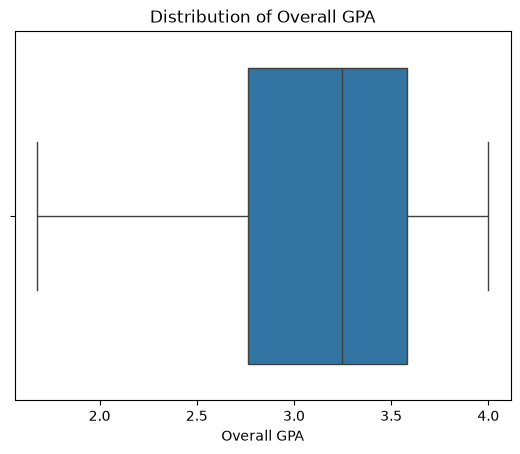

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('students.csv')

# Select a random sample of 150 students
sample = df.sample(n=150, replace=False, random_state=42)

# Create a box plot
sns.boxplot(x=sample['overall_gpa'])

plt.xlabel('Overall GPA')
plt.title('Distribution of Overall GPA')
plt.show()

#### c. Histogram

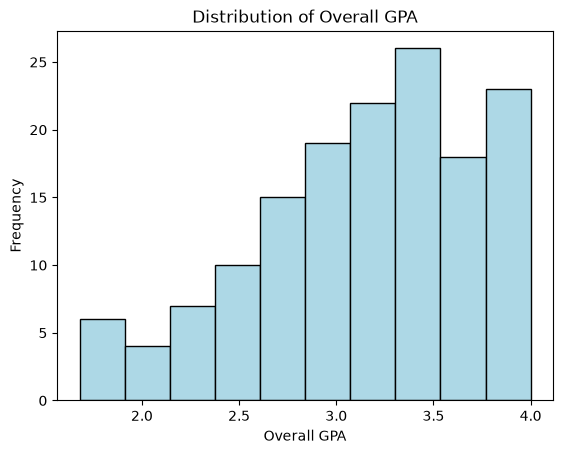

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('students.csv')

# Select a random sample of 150 students
sample = df.sample(n=150, replace=False, random_state=42)

# Create a histogram
plt.hist(sample['overall_gpa'], bins=10,
         color='lightblue', edgecolor='black')

plt.xlabel('Overall GPA')
plt.ylabel('Frequency')
plt.title('Distribution of Overall GPA')
plt.show()

#### d. Heat Map

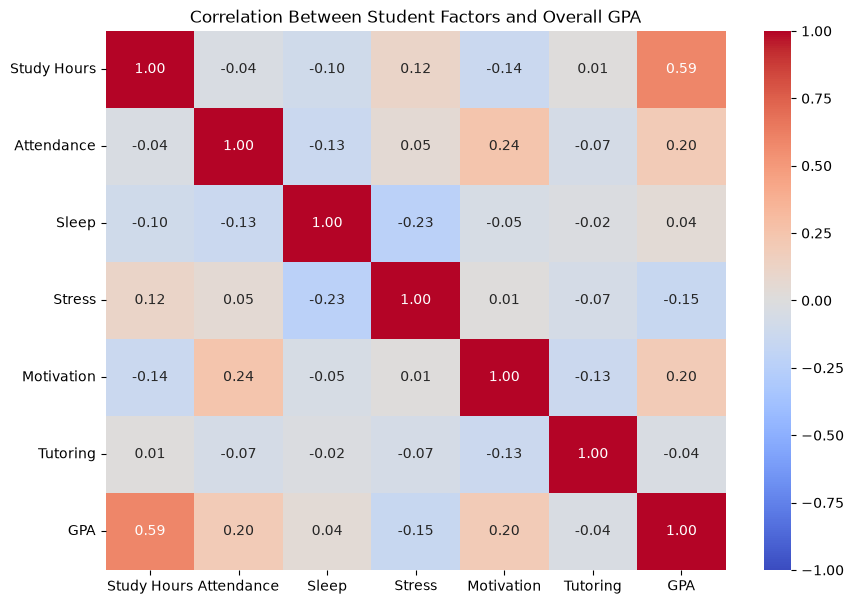

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('students.csv')

# Select a random sample of 150 students
sample = df.sample(n=150, replace=False, random_state=42)

# Select numerical variables
data = sample[['study_hours_per_week',
               'attendance_rate',
               'sleep_hours',
               'stress_level',
               'motivation_score',
               'tutoring_sessions',
               'overall_gpa']]

# Use shorter labels
data.columns = ['Study Hours', 'Attendance', 'Sleep',
                'Stress', 'Motivation', 'Tutoring', 'GPA']

# Create a heat map
plt.figure(figsize=(10, 7))
sns.heatmap(data.corr(), annot=True,
            fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1)

plt.title('Correlation Between Student Factors and Overall GPA')
plt.show()

### Question 6: Hypothesis Test

In [8]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr, shapiro

# Load the dataset
df = pd.read_csv("students.csv")

# Select a random sample of 150 students
sample = df.sample(n=150, replace=False, random_state=42)

# Select the numerical variables
x = sample["study_hours_per_week"]
y = sample["overall_gpa"]

# Check normality using the Shapiro test
study_stat, study_p = shapiro(x)
gpa_stat, gpa_p = shapiro(y)

# Pearson correlation
pearson_r, pearson_p = pearsonr(x, y)

# Spearman correlation
spearman_r, spearman_p = spearmanr(x, y)

# Display the results
print("Sample Size:", len(sample))
print("Study Hours Shapiro P-value:", round(study_p, 4))
print("GPA Shapiro P-value:", round(gpa_p, 4))

print("Pearson Correlation:", round(pearson_r, 4))
print("Pearson P-value:", f"{pearson_p:.2e}")

print("Spearman Correlation:", round(spearman_r, 4))
print("Spearman P-value:", f"{spearman_p:.2e}")

# Hypothesis decisions
if pearson_p < 0.05:
    print("Pearson: Reject H0.")
else:
    print("Pearson: Fail to reject H0.")

if spearman_p < 0.05:
    print("Spearman: Reject H0.")
else:
    print("Spearman: Fail to reject H0.")

Sample Size: 150
Study Hours Shapiro P-value: 0.0036
GPA Shapiro P-value: 0.0001
Pearson Correlation: 0.5904
Pearson P-value: 1.86e-15
Spearman Correlation: 0.5839
Spearman P-value: 4.39e-15
Pearson: Reject H0.
Spearman: Reject H0.


In [9]:
import pandas as pd
from scipy.stats import chi2_contingency

# Load the dataset
df = pd.read_csv("students.csv")

# Convert overall GPA into categories
df["gpa_group"] = "Below 3.0"
df.loc[df["overall_gpa"] >= 3.0, "gpa_group"] = "3.0 or above"

# Create a contingency table
contingency_table = pd.crosstab(
    df["parental_involvement"],
    df["gpa_group"]
)

print("Contingency Table:")
print(contingency_table)

# Perform the Chi-square test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

# Display results
print("Chi-square Statistic:", round(chi2_stat, 4))
print("P-value:", f"{p_value:.2e}")
print("Degrees of Freedom:", dof)
print("Minimum Expected Frequency:", round(expected.min(), 2))

# Hypothesis decision
if p_value < 0.05:
    print("Decision: Reject H0. There is a significant association.")
else:
    print("Decision: Fail to reject H0. No significant association found.")

Contingency Table:
gpa_group             3.0 or above  Below 3.0
parental_involvement                         
high                          2056        980
low                           1352       1152
medium                        2706       1754
Chi-square Statistic: 109.5715
P-value: 1.61e-24
Degrees of Freedom: 2
Minimum Expected Frequency: 973.05
Decision: Reject H0. There is a significant association.


### Question 7: One Sample T-test 

In [10]:
import pandas as pd
from scipy.stats import shapiro, ttest_1samp

# Load the dataset
df = pd.read_csv("students.csv")

# Find the mean GPA of the full dataset
population_mean = df['overall_gpa'].mean()

# Select the systematic sample
sample_size = 150
interval = len(df) // sample_size
systematic_sample = df.iloc[::interval].head(sample_size)

# Select the dependent variable
gpa = systematic_sample['overall_gpa']

# Check normality using Shapiro-Wilk test
shapiro_stat, shapiro_p = shapiro(gpa)

# Perform the one-sample t-test
t_stat, p_value = ttest_1samp(gpa, population_mean)

# Display the results
print("Sample Size:", len(gpa))
print("Sampling Interval:", interval)
print("Full Dataset Mean GPA:", round(population_mean, 6))
print("Systematic Sample Mean GPA:", round(gpa.mean(), 6))
print("Shapiro-Wilk Statistic:", round(shapiro_stat, 4))
print("Shapiro P-value:", round(shapiro_p, 4))
print("T-statistic:", round(t_stat, 4))
print("T-test P-value:", round(p_value, 4))
print("Degrees of Freedom:", len(gpa) - 1)

# Check normality
if shapiro_p < 0.05:
    print("Shapiro Decision: Not normally distributed.")
else:
    print("Shapiro Decision: No significant evidence against normality.")

# Hypothesis decision
if p_value < 0.05:
    print("T-test Decision: Reject H0.")
else:
    print("T-test Decision: Fail to reject H0.")

Sample Size: 150
Sampling Interval: 66
Full Dataset Mean GPA: 3.12389
Systematic Sample Mean GPA: 3.132867
Shapiro-Wilk Statistic: 0.9703
Shapiro P-value: 0.0024
T-statistic: 0.1972
T-test P-value: 0.844
Degrees of Freedom: 149
Shapiro Decision: Not normally distributed.
T-test Decision: Fail to reject H0.
